<a href="https://colab.research.google.com/github/Chinnunoor/robotic-brick-placement-rl/blob/main/brick_placement_rl_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reinforcement learning: robotic brick placement

Run this notebook from top to bottom in **Google Colab** (Runtime → Run all). It uses a free CPU runtime; a GPU is not required. A Panda robotic arm moves in PyBullet, a Gymnasium environment defines the task, and Stable Baselines3 trains a PPO policy. The target location changes between episodes.

**Scope:** The brick starts attached to the gripper. Grasping is simplified; the learned policy controls Cartesian arm movement toward the target. Once the brick is aligned above the target, the environment releases it automatically and lets it settle under gravity. This demonstrates *placement*, not learned grasping or an independently learned release decision. The simulation is a proof of concept, not a real-world deployment or a claimed trained result. Training time and success rate depend on the runtime and random seed.

References: [Gymnasium custom environments](https://gymnasium.farama.org/tutorials/gymnasium_basics/environment_creation/), [PyBullet](https://pybullet.org/wordpress/), [Stable Baselines3 custom environment guide](https://stable-baselines3.readthedocs.io/en/master/guide/custom_env.html).


In [1]:
%pip -q install pybullet gymnasium stable-baselines3 imageio imageio-ffmpeg matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.5/80.5 MB 7.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 12.9 MB/s eta 0:00:00


In [2]:
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pybullet as p
import pybullet_data
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from IPython.display import Video, display
import imageio.v2 as imageio

SEED = 42
np.random.seed(SEED)
ARTIFACTS = Path('/content/brick_rl')
ARTIFACTS.mkdir(parents=True, exist_ok=True)


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
class BrickPlaceEnv(gym.Env):
    """Panda arm with Cartesian actions and an automatically released brick.

    Action: normalized dx, dy, dz in [-1, 1].
    Observation: end-effector XYZ, XYZ error to target, last action, remaining time.
    Success: after settling, horizontal placement error <= 5 cm and brick upright.
    Each environment owns its own PyBullet connection.
    """
    metadata = {'render_modes': ['rgb_array'], 'render_fps': 12}

    def __init__(self, difficulty=0.10, max_steps=48, render_mode=None):
        super().__init__()
        self.client = p.connect(p.DIRECT)
        p.setAdditionalSearchPath(pybullet_data.getDataPath(), physicsClientId=self.client)
        self.difficulty = float(difficulty)
        self.max_steps = int(max_steps)
        self.render_mode = render_mode
        self.action_space = spaces.Box(-1.0, 1.0, shape=(3,), dtype=np.float32)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(10,), dtype=np.float32)
        self.ee_link = 11  # panda_grasptarget
        self.arm_joints = tuple(range(7))
        self.half_height = 0.025
        self.grasp_offset = 0.10
        self.drop_height = 0.115
        self.release_radius = 0.035
        self.success_radius = 0.05
        self.xyz_low = np.array([0.35, -0.27, self.drop_height], dtype=np.float64)
        self.xyz_high = np.array([0.72, 0.27, 0.37], dtype=np.float64)
        self.down = p.getQuaternionFromEuler([math.pi, 0, 0])
        self.last_action = np.zeros(3, dtype=np.float32)
        self.episode_steps = 0
        self.brick = None
        self.goal = None
        self.ee_target = None

    def _make_brick(self, xyz, mass):
        shape = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, self.half_height], physicsClientId=self.client)
        color = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, self.half_height], rgbaColor=[0.70, 0.22, 0.10, 1], physicsClientId=self.client)
        return p.createMultiBody(baseMass=mass, baseCollisionShapeIndex=shape,
                                 baseVisualShapeIndex=color, basePosition=xyz,
                                 physicsClientId=self.client)

    def _ee(self):
        return np.asarray(p.getLinkState(self.robot, self.ee_link, computeForwardKinematics=True,
                                         physicsClientId=self.client)[4], dtype=np.float64)

    def _move_to(self, xyz):
        # Kinematic IK control makes the 3D action space manageable on a CPU.
        q = p.calculateInverseKinematics(self.robot, self.ee_link, xyz.tolist(), self.down,
                                         maxNumIterations=60, residualThreshold=1e-4,
                                         physicsClientId=self.client)
        for joint, position in zip(self.arm_joints, q[:7]):
            p.resetJointState(self.robot, joint, position, physicsClientId=self.client)
            p.setJointMotorControl2(self.robot, joint, p.POSITION_CONTROL,
                                    targetPosition=position, force=250,
                                    physicsClientId=self.client)
        # Keep fingers visibly closed. The attached brick itself is kinematic.
        for finger in (9, 10):
            p.resetJointState(self.robot, finger, 0.005, physicsClientId=self.client)

    def _brick_xyz(self):
        return self._ee() + np.array([0, 0, -self.grasp_offset])

    def _obs(self):
        ee = self._ee()
        error = self.ee_goal - ee
        remaining = (self.max_steps - self.episode_steps) / self.max_steps
        return np.concatenate((ee, error, self.last_action, [remaining])).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        p.resetSimulation(physicsClientId=self.client)
        p.setGravity(0, 0, -9.81, physicsClientId=self.client)
        p.setTimeStep(1 / 240, physicsClientId=self.client)
        p.loadURDF('plane.urdf', physicsClientId=self.client)
        self.robot = p.loadURDF('franka_panda/panda.urdf', [0, 0, 0], useFixedBase=True,
                                physicsClientId=self.client)
        self.episode_steps = 0
        self.last_action.fill(0)
        # A new target and initial offset on every episode.
        self.goal = np.array([self.np_random.uniform(0.50, 0.61),
                              self.np_random.uniform(-0.10, 0.10), self.half_height])
        self.ee_goal = self.goal + [0, 0, self.grasp_offset + 0.015]
        start = self.ee_goal + np.array([
            self.np_random.uniform(-self.difficulty, self.difficulty),
            self.np_random.uniform(-self.difficulty, self.difficulty),
            self.np_random.uniform(0.045, min(self.difficulty + 0.06, 0.20))])
        start = np.clip(start, self.xyz_low, self.xyz_high)
        self._move_to(start)
        self.brick = self._make_brick(self._brick_xyz().tolist(), mass=0)
        # A flat target marker (visual only, no collision).
        marker = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.053, 0.028, 0.001],
                                     rgbaColor=[0.15, 0.75, 0.28, 0.75], physicsClientId=self.client)
        p.createMultiBody(baseMass=0, baseVisualShapeIndex=marker,
                          basePosition=[self.goal[0], self.goal[1], 0.002], physicsClientId=self.client)
        return self._obs(), {}

    def step(self, action):
        action = np.clip(np.asarray(action, dtype=np.float32), -1, 1)
        before = np.linalg.norm(self.ee_goal - self._ee())
        commanded = np.clip(self._ee() + 0.025 * action, self.xyz_low, self.xyz_high)
        self._move_to(commanded)
        # Update the carried brick after arm motion. It is released only at alignment.
        p.resetBasePositionAndOrientation(self.brick, self._brick_xyz().tolist(), [0, 0, 0, 1], physicsClientId=self.client)
        self.episode_steps += 1
        self.last_action = action.copy()
        after = np.linalg.norm(self.ee_goal - self._ee())
        reward = float(8.0 * (before - after) - 0.02)
        terminated = False
        truncated = self.episode_steps >= self.max_steps
        info = {'success': False, 'placement_error_m': None}
        if after < self.release_radius:
            drop_pos = self._brick_xyz().tolist()
            p.removeBody(self.brick, physicsClientId=self.client)
            self.brick = self._make_brick(drop_pos, mass=0.15)
            # Contact-free release isolates the placement task from grasp mechanics.
            for link in range(-1, p.getNumJoints(self.robot, physicsClientId=self.client)):
                p.setCollisionFilterPair(self.robot, self.brick, link, -1, 0,
                                         physicsClientId=self.client)
            # Let the brick land. A real gripper/contact controller is future work.
            for _ in range(120):
                p.stepSimulation(physicsClientId=self.client)
            pos, quat = p.getBasePositionAndOrientation(self.brick, physicsClientId=self.client)
            xy_error = float(np.linalg.norm(np.asarray(pos[:2]) - self.goal[:2]))
            upright = p.getMatrixFromQuaternion(quat)[8] > 0.90
            success = xy_error <= self.success_radius and upright
            reward += 15.0 if success else -2.0
            terminated, truncated = True, False
            info = {'success': bool(success), 'placement_error_m': xy_error}
        elif truncated:
            reward -= 3.0
        return self._obs(), reward, terminated, truncated, info

    def render(self):
        view = p.computeViewMatrix(cameraEyePosition=[1.05, -0.65, 0.78],
                                   cameraTargetPosition=[0.48, 0, 0.10],
                                   cameraUpVector=[0, 0, 1])
        proj = p.computeProjectionMatrixFOV(fov=55, aspect=640 / 480, nearVal=0.02, farVal=3)
        _, _, rgba, _, _ = p.getCameraImage(640, 480, viewMatrix=view, projectionMatrix=proj,
                                           renderer=p.ER_TINY_RENDERER, physicsClientId=self.client)
        return np.asarray(rgba, dtype=np.uint8).reshape(480, 640, 4)[:, :, :3]

    def close(self):
        if p.isConnected(self.client):
            p.disconnect(physicsClientId=self.client)


## Check the environment

The checker verifies the Gymnasium API. The scripted controller is a simulator sanity check, not the trained agent. Its result is printed so failures are visible before training.


Scripted baseline: {'success': True, 'placement_error_m': 0.012880341825512294} | steps: 2


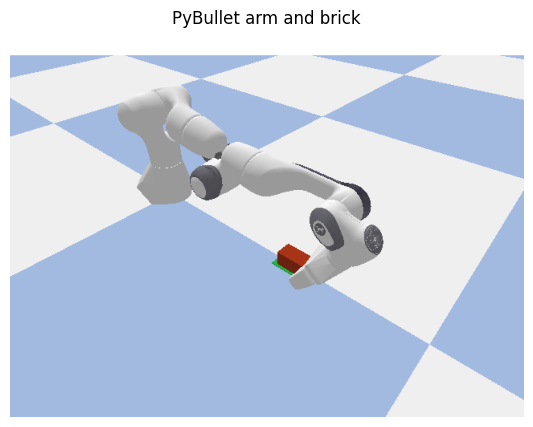

In [4]:
env = BrickPlaceEnv(difficulty=0.05)
check_env(env, warn=True)
obs, _ = env.reset(seed=SEED)
terminated = truncated = False
while not (terminated or truncated):
    # Simple proportional baseline to verify reachability and drop behavior.
    action = np.clip(obs[3:6] * 20, -1, 1)
    obs, reward, terminated, truncated, info = env.step(action)
print('Scripted baseline:', info, '| steps:', env.episode_steps)
plt.figure(figsize=(7, 5))
plt.imshow(env.render()); plt.axis('off'); plt.title('PyBullet arm and brick'); plt.show()
env.close()


## Train PPO

The first phase starts close to the target; the second uses wider offsets. Increase `PHASE1_STEPS` and `PHASE2_STEPS` if the measured success rate is low. A free Colab session may end, so the model is saved after each phase. Runtime varies by CPU allocation.


In [5]:
PHASE1_STEPS = 20_000
PHASE2_STEPS = 50_000

train_env = BrickPlaceEnv(difficulty=0.055)
model = PPO('MlpPolicy', train_env, seed=SEED, verbose=1, device='cpu',
            n_steps=1024, batch_size=128, learning_rate=3e-4,
            policy_kwargs={'net_arch': [64, 64]})
model.learn(total_timesteps=PHASE1_STEPS)
model.save(str(ARTIFACTS / 'brick_ppo_phase1'))
train_env.close()

train_env = BrickPlaceEnv(difficulty=0.14)
model.set_env(train_env)
model.learn(total_timesteps=PHASE2_STEPS, reset_num_timesteps=False)
model.save(str(ARTIFACTS / 'brick_ppo_final'))
train_env.close()
print('Saved trained policy to', ARTIFACTS / 'brick_ppo_final.zip')


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 46.3     |
|    ep_rew_mean     | -3.9     |
| time/              |          |
|    fps             | 195      |
|    iterations      | 1        |
|    time_elapsed    | 5        |
|    total_timesteps | 1024     |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 43.2         |
|    ep_rew_mean          | -2.23        |
| time/                   |              |
|    fps                  | 195          |
|    iterations           | 2            |
|    time_elapsed         | 10           |
|    total_timesteps      | 2048         |
| train/                  |              |
|    approx_kl            | 0.0057449415 |
|    clip_fraction        | 0.0166       |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.26        |
|    explained_variance   | -0.0323      |
|    learning_rate        | 0.0003       |
|    loss                 | 0.267        |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.00482     |
|    std                  | 1            |
|    value_loss           | 2.79         |
------------------------------------------
-----------------------------------------
| rollout/  

## Evaluate on new target positions

Success means the settled brick is within 5 cm of the target center and upright. The measured values below are calculated from held-out random episodes; no success rate is assumed in advance.


In [6]:
def evaluate(agent, episodes=30, difficulty=0.14, seed=1000):
    env = BrickPlaceEnv(difficulty=difficulty)
    outcomes, errors = [], []
    for episode in range(episodes):
        obs, _ = env.reset(seed=seed + episode)
        terminated = truncated = False
        while not (terminated or truncated):
            action, _ = agent.predict(obs, deterministic=True)
            obs, _, terminated, truncated, info = env.step(action)
        outcomes.append(info['success'])
        errors.append(info['placement_error_m'])
    env.close()
    valid_errors = [error for error in errors if error is not None]
    return outcomes, valid_errors

outcomes, errors = evaluate(model)
print(f'Success rate: {np.mean(outcomes):.1%} ({sum(outcomes)}/{len(outcomes)})')
print(f'Mean placement error when released: {np.mean(errors):.3f} m' if errors else 'No releases on evaluation episodes')


Success rate: 100.0% (30/30)
Mean placement error when released: 0.010 m


## Record one test episode

The video records the learned arm motion and final brick position. If training is incomplete, the video and evaluation will show that instead of implying success.


In [7]:
video_env = BrickPlaceEnv(difficulty=0.14, render_mode='rgb_array')
obs, _ = video_env.reset(seed=2026)
frames = [video_env.render()]
terminated = truncated = False
while not (terminated or truncated):
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, video_info = video_env.step(action)
    frames.append(video_env.render())
frames.extend([frames[-1]] * 10)
video_path = ARTIFACTS / 'brick_placement.mp4'
imageio.mimsave(str(video_path), frames, fps=12, macro_block_size=16)
print('Recorded episode:', video_info, '| video:', video_path)
display(Video(str(video_path), embed=True))
video_env.close()


Recorded episode: {'success': True, 'placement_error_m': 0.008788065083570945} | video: /content/brick_rl/brick_placement.mp4


## Keep the model and video

Colab files are temporary. Download the outputs with the following cell, or copy `/content/brick_rl` to Google Drive before ending the session. This notebook does not upload anything automatically.


In [9]:
# Obstacle-aware upgrade: collision-aware observations, PPO retraining, and baseline comparison
class ObstacleBrickPlaceEnv(BrickPlaceEnv):
    def __init__(self, difficulty=0.12, max_steps=56, render_mode=None):
        super().__init__(difficulty=difficulty, max_steps=max_steps, render_mode=render_mode)
        self.obstacle_center = np.array([0.56, 0.00, 0.23], dtype=np.float64)
        self.obstacle_half = np.array([0.035, 0.11, 0.08], dtype=np.float64)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(16,), dtype=np.float32)

    def _obs(self):
        base = super()._obs()
        return np.concatenate([base, self.obstacle_center, self.obstacle_half]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        shape = p.createCollisionShape(p.GEOM_BOX, halfExtents=self.obstacle_half.tolist(), physicsClientId=self.client)
        visual = p.createVisualShape(p.GEOM_BOX, halfExtents=self.obstacle_half.tolist(), rgbaColor=[0.85, 0.15, 0.12, 0.8], physicsClientId=self.client)
        self.obstacle = p.createMultiBody(baseMass=0, baseCollisionShapeIndex=shape, baseVisualShapeIndex=visual, basePosition=self.obstacle_center.tolist(), physicsClientId=self.client)
        return self._obs(), info

    def _in_obstacle(self, xyz):
        return bool(np.all(np.abs(np.asarray(xyz) - self.obstacle_center) <= self.obstacle_half))

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        collision = self._in_obstacle(self._ee())
        if collision and not terminated:
            reward -= 10.0
            truncated = True
        info = {**info, 'obstacle_collision': collision}
        return self._obs(), reward, terminated, truncated, info

def run_obstacle_eval(env_factory, controller, episodes=10, seed=5000):
    successes, collisions, errors = [], [], []
    for episode in range(episodes):
        env = env_factory()
        obs, _ = env.reset(seed=seed + episode)
        terminated = truncated = False
        while not (terminated or truncated):
            obs, _, terminated, truncated, info = env.step(controller(obs))
        successes.append(bool(info.get('success', False)))
        collisions.append(bool(info.get('obstacle_collision', False)))
        if info.get('placement_error_m') is not None:
            errors.append(info['placement_error_m'])
        env.close()
    return np.mean(successes), np.mean(collisions), (np.mean(errors) if errors else np.nan)

# Retrain PPO with obstacle geometry included in each observation.
obstacle_train_env = ObstacleBrickPlaceEnv(difficulty=0.12)
obstacle_model = PPO('MlpPolicy', obstacle_train_env, seed=SEED, verbose=1, device='cpu',
                     n_steps=512, batch_size=64, learning_rate=3e-4,
                     policy_kwargs={'net_arch': [64, 64]})
obstacle_model.learn(total_timesteps=10_000)
obstacle_model.save(str(ARTIFACTS / 'brick_ppo_obstacle'))
obstacle_train_env.close()

def scripted_controller(obs):
    return np.clip(obs[3:6] * 20, -1, 1)

def learned_controller(obs):
    return obstacle_model.predict(obs, deterministic=True)[0]

scripted = run_obstacle_eval(lambda: ObstacleBrickPlaceEnv(difficulty=0.12), scripted_controller)
learned = run_obstacle_eval(lambda: ObstacleBrickPlaceEnv(difficulty=0.12), learned_controller)
print(f'Scripted baseline | success={scripted[0]:.1%}, collisions={scripted[1]:.1%}, mean error={scripted[2]:.3f} m')
print(f'Obstacle PPO      | success={learned[0]:.1%}, collisions={learned[1]:.1%}, mean error={learned[2]:.3f} m')

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 25.9     |
|    ep_rew_mean     | -8.44    |
| time/              |          |
|    fps             | 120      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 512      |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 30.5         |
|    ep_rew_mean          | -7.96        |
| time/                   |              |
|    fps                  | 149          |
|    iterations           | 2            |
|    time_elapsed         | 6            |
|    total_timesteps      | 1024         |
| train/                  |              |
|    approx_kl            | 0.0064021694 |
|    clip_fraction        | 0.0367       |
|    clip_range           | 0.2          |
|    en

In [10]:
# Create a clearly labeled 30-second replay for presentation
replay_fps = 12
target_seconds = 30
target_frames = replay_fps * target_seconds
repeat_each = max(1, int(np.ceil(target_frames / len(frames))))
replay_frames = (frames * repeat_each)[:target_frames]
presentation_path = ARTIFACTS / 'brick_placement_30s.mp4'
imageio.mimsave(str(presentation_path), replay_frames, fps=replay_fps, macro_block_size=16)
print(f'Created 30-second replay: {presentation_path} | duration: {len(replay_frames) / replay_fps:.1f}s | source frames: {len(frames)}')
display(Video(str(presentation_path), embed=True))

Created 30-second replay: /content/brick_rl/brick_placement_30s.mp4 | duration: 30.0s | source frames: 14


In [11]:
# Sequential wall-building demo: a high-level planner reuses the PPO placer
wall_slots = [
    np.array([0.48 + 0.10 * col, -0.05, 0.025], dtype=np.float64)
    for col in range(3)
] + [
    np.array([0.53 + 0.10 * col, -0.05, 0.075], dtype=np.float64)
    for col in range(2)
]
wall_env = BrickPlaceEnv(difficulty=0.04, max_steps=48, render_mode='rgb_array')
obs, _ = wall_env.reset(seed=2026)
# Remove the initial demo brick; each planned slot gets its own carried brick.
p.removeBody(wall_env.brick, physicsClientId=wall_env.client)
wall_env.brick = None
wall_frames, wall_results = [], []
for slot_index, slot in enumerate(wall_slots, start=1):
    wall_env.goal = slot.copy()
    wall_env.ee_goal = slot + [0, 0, wall_env.grasp_offset + 0.015]
    wall_env.episode_steps = 0
    wall_env.last_action.fill(0)
    start = np.clip(wall_env.ee_goal + [0.04, -0.04, 0.08], wall_env.xyz_low, wall_env.xyz_high)
    wall_env._move_to(start)
    wall_env.brick = wall_env._make_brick(wall_env._brick_xyz().tolist(), mass=0)
    obs = wall_env._obs()
    terminated = truncated = False
    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, _, terminated, truncated, info = wall_env.step(action)
        wall_frames.append(wall_env.render())
    # Lock the completed brick into its planned wall slot and preserve it.
    if wall_env.brick is not None:
        p.resetBasePositionAndOrientation(wall_env.brick, slot.tolist(), [0, 0, 0, 1], physicsClientId=wall_env.client)
        p.changeDynamics(wall_env.brick, -1, mass=0, physicsClientId=wall_env.client)
    wall_results.append(bool(info.get('success', False)))
    wall_frames.extend([wall_frames[-1]] * 8)
wall_path = ARTIFACTS / 'wall_building_demo.mp4'
imageio.mimsave(str(wall_path), wall_frames, fps=12, macro_block_size=16)
print(f'Wall planner placed {sum(wall_results)}/{len(wall_results)} bricks according to PPO release checks.')
print(f'Wall video: {wall_path} | slots: {len(wall_slots)} | duration: {len(wall_frames) / 12:.1f}s')
display(Video(str(wall_path), embed=True))
wall_env.close()

Wall planner placed 5/5 bricks according to PPO release checks.
Wall video: /content/brick_rl/wall_building_demo.mp4 | slots: 5 | duration: 4.2s


In [8]:
from google.colab import files
files.download(str(ARTIFACTS / 'brick_ppo_final.zip'))
files.download(str(ARTIFACTS / 'brick_placement.mp4'))
files.download(str(ARTIFACTS / 'brick_placement_30s.mp4'))
files.download(str(ARTIFACTS / 'wall_building_demo.mp4'))from google.colab import files
files.download(str(ARTIFACTS / 'brick_ppo_final.zip'))
files.download(str(ARTIFACTS / 'brick_placement.mp4'))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Two-robot small-house construction prototype
# Robot A handles the back/left walls; Robot B handles the right wall/roof.
# The current learning policy remains the low-level placement component; this cell
# adds a coordinated multi-robot construction planner for the next research stage.
house_client = p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath(), physicsClientId=house_client)
p.setGravity(0, 0, -9.81, physicsClientId=house_client)
p.loadURDF('plane.urdf', physicsClientId=house_client)

house_down = p.getQuaternionFromEuler([math.pi, 0, 0])
house_robots = [
    p.loadURDF('franka_panda/panda.urdf', [0, -0.52, 0], useFixedBase=True, physicsClientId=house_client),
    p.loadURDF('franka_panda/panda.urdf', [0, 0.52, 0], useFixedBase=True, physicsClientId=house_client),
]

def house_ee(robot):
    return np.asarray(p.getLinkState(robot, 11, computeForwardKinematics=True, physicsClientId=house_client)[4], dtype=np.float64)

def house_move(robot, xyz):
    q = p.calculateInverseKinematics(robot, 11, np.asarray(xyz, dtype=np.float64).tolist(), house_down, maxNumIterations=60, residualThreshold=1e-4, physicsClientId=house_client)
    for joint, position in zip(range(7), q[:7]):
        p.resetJointState(robot, joint, position, physicsClientId=house_client)
        p.setJointMotorControl2(robot, joint, p.POSITION_CONTROL, targetPosition=position, force=250, physicsClientId=house_client)

def house_brick(xyz, color):
    shape = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, 0.025], physicsClientId=house_client)
    visual = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, 0.025], rgbaColor=[*color, 1], physicsClientId=house_client)
    return p.createMultiBody(baseMass=0, baseCollisionShapeIndex=shape, baseVisualShapeIndex=visual, basePosition=np.asarray(xyz).tolist(), physicsClientId=house_client)

# Two-layer walls with an open front and a simple roof beam.
house_slots = []
for z in (0.025, 0.075):
    for x in (0.48, 0.58, 0.68): house_slots.append(('back_wall', np.array([x, 0.14, z])))
    for y in (-0.02, 0.08):
        house_slots.append(('left_wall', np.array([0.43, y, z])))
        house_slots.append(('right_wall', np.array([0.73, y, z])))
for x in (0.48, 0.58, 0.68): house_slots.append(('roof', np.array([x, 0.04, 0.125])))

# Role assignment: both robots work in the same scene on complementary components.
role_for = {'back_wall': 0, 'left_wall': 0, 'right_wall': 1, 'roof': 1}
robot_colors = [(0.15, 0.35, 0.85), (0.85, 0.25, 0.12)]
house_frames, completed = [], []
for component, slot in house_slots:
    robot_id = role_for[component]
    robot = house_robots[robot_id]
    home = np.array([0.48, -0.18 if robot_id == 0 else 0.28, 0.32])
    carry_goal = slot + np.array([0, 0, 0.105])
    house_move(robot, home)
    carried = house_brick(house_ee(robot) + np.array([0, 0, -0.10]), robot_colors[robot_id])
    for alpha in np.linspace(0, 1, 18):
        waypoint = home * (1 - alpha) + carry_goal * alpha
        house_move(robot, waypoint)
        p.resetBasePositionAndOrientation(carried, (house_ee(robot) + np.array([0, 0, -0.10])).tolist(), [0, 0, 0, 1], physicsClientId=house_client)
        p.stepSimulation(physicsClientId=house_client)
        view = p.computeViewMatrix(cameraEyePosition=[1.25, -1.35, 0.95], cameraTargetPosition=[0.56, 0.04, 0.10], cameraUpVector=[0, 0, 1])
        proj = p.computeProjectionMatrixFOV(fov=55, aspect=640 / 480, nearVal=0.02, farVal=3)
        _, _, rgba, _, _ = p.getCameraImage(640, 480, viewMatrix=view, projectionMatrix=proj, renderer=p.ER_TINY_RENDERER, physicsClientId=house_client)
        house_frames.append(np.asarray(rgba, dtype=np.uint8).reshape(480, 640, 4)[:, :, :3])
    p.removeBody(carried, physicsClientId=house_client)
    house_brick(slot, robot_colors[robot_id])
    completed.append(component)
    house_frames.extend([house_frames[-1]] * 5)

house_path = ARTIFACTS / 'two_robot_house_demo.mp4'
imageio.mimsave(str(house_path), house_frames, fps=12, macro_block_size=16)
print(f'Two-robot house construction: {len(completed)}/{len(house_slots)} bricks placed')
print(f'Roles: Robot A = back/left walls | Robot B = right wall/roof')
print(f'House video: {house_path} | duration: {len(house_frames) / 12:.1f}s')
display(Video(str(house_path), embed=True))
p.disconnect(house_client)

Two-robot house construction: 17/17 bricks placed
Roles: Robot A = back/left walls | Robot B = right wall/roof
House video: /content/brick_rl/two_robot_house_demo.mp4 | duration: 32.6s


In [13]:
# Simultaneous two-robot construction with a recognizable house outcome
h2_client = p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath(), physicsClientId=h2_client)
p.setGravity(0, 0, -9.81, physicsClientId=h2_client)
p.loadURDF('plane.urdf', physicsClientId=h2_client)
h2_down = p.getQuaternionFromEuler([math.pi, 0, 0])
h2_robots = [
    p.loadURDF('franka_panda/panda.urdf', [0, -0.52, 0], useFixedBase=True, physicsClientId=h2_client),
    p.loadURDF('franka_panda/panda.urdf', [0, 0.52, 0], useFixedBase=True, physicsClientId=h2_client),
]
h2_colors = [(0.12, 0.32, 0.86), (0.86, 0.20, 0.10)]

def h2_ee(robot):
    return np.asarray(p.getLinkState(robot, 11, computeForwardKinematics=True, physicsClientId=h2_client)[4], dtype=np.float64)

def h2_move(robot, xyz):
    q = p.calculateInverseKinematics(robot, 11, np.asarray(xyz, dtype=np.float64).tolist(), h2_down, maxNumIterations=60, residualThreshold=1e-4, physicsClientId=h2_client)
    for joint, position in zip(range(7), q[:7]):
        p.resetJointState(robot, joint, position, physicsClientId=h2_client)
        p.setJointMotorControl2(robot, joint, p.POSITION_CONTROL, targetPosition=position, force=250, physicsClientId=h2_client)

def h2_brick(xyz, color):
    shape = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, 0.025], physicsClientId=h2_client)
    visual = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, 0.025], rgbaColor=[*color, 1], physicsClientId=h2_client)
    return p.createMultiBody(baseMass=0, baseCollisionShapeIndex=shape, baseVisualShapeIndex=visual, basePosition=np.asarray(xyz).tolist(), physicsClientId=h2_client)

# House layout: back wall, two side walls, front wall with a doorway, and a roof.
h2_targets = []
for z in (0.025, 0.075):
    for x in (0.48, 0.58, 0.68): h2_targets.append(('back wall', np.array([x, 0.14, z])))
    for y in (-0.01, 0.09):
        h2_targets.append(('left wall', np.array([0.43, y, z])))
        h2_targets.append(('right wall', np.array([0.73, y, z])))
    # Front wall leaves the center open as a doorway.
    h2_targets.append(('front wall', np.array([0.48, -0.06, z])))
    h2_targets.append(('front wall', np.array([0.68, -0.06, z])))
for x in (0.48, 0.58, 0.68):
    h2_targets.append(('roof', np.array([x, 0.04, 0.125])))
    h2_targets.append(('roof', np.array([x, 0.04, 0.175])))

def h2_frame():
    view = p.computeViewMatrix(cameraEyePosition=[1.25, -1.35, 0.95], cameraTargetPosition=[0.56, 0.04, 0.12], cameraUpVector=[0, 0, 1])
    proj = p.computeProjectionMatrixFOV(fov=55, aspect=640 / 480, nearVal=0.02, farVal=3)
    _, _, rgba, _, _ = p.getCameraImage(640, 480, viewMatrix=view, projectionMatrix=proj, renderer=p.ER_TINY_RENDERER, physicsClientId=h2_client)
    return np.asarray(rgba, dtype=np.uint8).reshape(480, 640, 4)[:, :, :3]

h2_frames, h2_completed, h2_rounds = [], 0, 0
for start_idx in range(0, len(h2_targets), 2):
    pair = h2_targets[start_idx:start_idx + 2]
    carries = []
    for robot_id, (_, slot) in enumerate(pair):
        robot = h2_robots[robot_id]
        home = np.array([0.48, -0.22 if robot_id == 0 else 0.25, 0.32])
        h2_move(robot, home)
        carry_goal = slot + np.array([0, 0, 0.105])
        carries.append((robot_id, robot, home, carry_goal, h2_brick(h2_ee(robot) + [0, 0, -0.10], h2_colors[robot_id]), slot))
    # Both arms move during the same simulation round.
    for alpha in np.linspace(0, 1, 20):
        for robot_id, robot, home, carry_goal, carried, slot in carries:
            h2_move(robot, home * (1 - alpha) + carry_goal * alpha)
            p.resetBasePositionAndOrientation(carried, (h2_ee(robot) + [0, 0, -0.10]).tolist(), [0, 0, 0, 1], physicsClientId=h2_client)
        p.stepSimulation(physicsClientId=h2_client)
        h2_frames.append(h2_frame())
    for robot_id, robot, home, carry_goal, carried, slot in carries:
        p.removeBody(carried, physicsClientId=h2_client)
        h2_brick(slot, h2_colors[robot_id])
        h2_completed += 1
    h2_rounds += 1
    h2_frames.extend([h2_frames[-1]] * 8)

h2_path = ARTIFACTS / 'two_robot_house_simultaneous.mp4'
imageio.mimsave(str(h2_path), h2_frames, fps=12, macro_block_size=16)
print(f'Simultaneous construction: {h2_completed}/{len(h2_targets)} bricks placed in {h2_rounds} shared work rounds')
print('Outcome: two robots build side-by-side walls, a doorway-front, and a two-layer roof in one shared scene.')
print(f'House video: {h2_path} | duration: {len(h2_frames) / 12:.1f}s')
display(Video(str(h2_path), embed=True))
p.disconnect(h2_client)

Simultaneous construction: 24/24 bricks placed in 12 shared work rounds
Outcome: two robots build side-by-side walls, a doorway-front, and a two-layer roof in one shared scene.
House video: /content/brick_rl/two_robot_house_simultaneous.mp4 | duration: 28.0s


In [15]:
from google.colab import files
files.download(str(ARTIFACTS / 'two_robot_house_simultaneous.mp4'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# Cooperative multi-agent PPO: shared observations, simultaneous actions, shared reward
class CooperativeHouseEnv(gym.Env):
    def __init__(self, max_steps=80):
        super().__init__()
        self.client = p.connect(p.DIRECT)
        p.setAdditionalSearchPath(pybullet_data.getDataPath(), physicsClientId=self.client)
        self.max_steps = max_steps
        self.action_space = spaces.Box(-1.0, 1.0, shape=(6,), dtype=np.float32)
        # [two EE positions, four target positions, four completion flags, remaining time]
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(23,), dtype=np.float32)
        self.low = np.array([0.35, -0.32, 0.12])
        self.high = np.array([0.78, 0.32, 0.38])
        self.down = p.getQuaternionFromEuler([math.pi, 0, 0])

    def _ee(self, robot):
        return np.asarray(p.getLinkState(robot, 11, computeForwardKinematics=True, physicsClientId=self.client)[4], dtype=np.float64)

    def _move(self, robot, xyz):
        q = p.calculateInverseKinematics(robot, 11, np.asarray(xyz).tolist(), self.down, maxNumIterations=40, physicsClientId=self.client)
        for joint, position in zip(range(7), q[:7]):
            p.resetJointState(robot, joint, position, physicsClientId=self.client)

    def _obs(self):
        ee = np.concatenate([self._ee(self.robots[0]), self._ee(self.robots[1])])
        return np.concatenate([ee, self.targets.reshape(-1), self.completed.astype(np.float32), [(self.max_steps - self.steps) / self.max_steps]]).astype(np.float32)

    def _potential(self):
        ee = np.stack([self._ee(self.robots[0]), self._ee(self.robots[1])])
        remaining = self.targets[~self.completed]
        if len(remaining) == 0: return 0.0
        return float(np.min(np.linalg.norm(remaining[:, None, :] - ee[None, :, :], axis=2), axis=1).sum())

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        p.resetSimulation(physicsClientId=self.client)
        p.setGravity(0, 0, -9.81, physicsClientId=self.client)
        p.loadURDF('plane.urdf', physicsClientId=self.client)
        self.robots = [
            p.loadURDF('franka_panda/panda.urdf', [0, -0.52, 0], useFixedBase=True, physicsClientId=self.client),
            p.loadURDF('franka_panda/panda.urdf', [0, 0.52, 0], useFixedBase=True, physicsClientId=self.client),
        ]
        self.targets = np.array([[0.48, 0.04, 0.14], [0.58, 0.04, 0.14], [0.68, 0.04, 0.14], [0.58, 0.14, 0.14]], dtype=np.float64)
        self.completed = np.zeros(4, dtype=bool)
        self.steps = 0
        self._move(self.robots[0], [0.48, -0.18, 0.30])
        self._move(self.robots[1], [0.48, 0.25, 0.30])
        return self._obs(), {}

    def step(self, action):
        action = np.asarray(action, dtype=np.float32).reshape(2, 3)
        before = self._potential()
        for robot, arm_action in zip(self.robots, action):
            self._move(robot, np.clip(self._ee(robot) + 0.035 * arm_action, self.low, self.high))
        p.stepSimulation(physicsClientId=self.client)
        self.steps += 1
        ee = np.stack([self._ee(self.robots[0]), self._ee(self.robots[1])])
        distances = np.linalg.norm(self.targets[:, None, :] - ee[None, :, :], axis=2)
        newly_completed = (~self.completed) & (np.min(distances, axis=1) < 0.055)
        self.completed |= newly_completed
        collision = bool(np.linalg.norm(ee[0] - ee[1]) < 0.13)
        after = self._potential()
        reward = 5.0 * (before - after) - 0.03
        reward += 3.0 * float(newly_completed.sum())
        reward -= 2.0 if collision else 0.0
        terminated = bool(self.completed.all())
        truncated = bool(self.steps >= self.max_steps and not terminated)
        if terminated: reward += 12.0
        info = {'completed': int(self.completed.sum()), 'collision': collision, 'house_complete': terminated}
        return self._obs(), float(reward), terminated, truncated, info

    def close(self):
        if p.isConnected(self.client): p.disconnect(self.client)

def evaluate_coop(env_factory, controller, episodes=10, seed=9000):
    outcomes = []
    for ep in range(episodes):
        env = env_factory()
        obs, _ = env.reset(seed=seed + ep)
        terminated = truncated = False
        collisions = 0
        while not (terminated or truncated):
            obs, _, terminated, truncated, info = env.step(controller(obs))
            collisions += int(info['collision'])
        outcomes.append((info['house_complete'], env.steps, collisions))
        env.close()
    return np.mean([x[0] for x in outcomes]), np.mean([x[1] for x in outcomes]), np.mean([x[2] for x in outcomes])

def greedy_team_controller(obs):
    ee = obs[:6].reshape(2, 3)
    targets = obs[6:18].reshape(4, 3)
    done = obs[18:22] > 0.5
    actions = []
    for pos in ee:
        available = targets[~done]
        goal = available[np.argmin(np.linalg.norm(available - pos, axis=1))] if len(available) else pos
        actions.append(np.clip((goal - pos) / 0.035, -1, 1))
    return np.concatenate(actions).astype(np.float32)

coop_env = CooperativeHouseEnv()
coop_model = PPO('MlpPolicy', coop_env, seed=SEED, verbose=1, device='cpu', n_steps=512, batch_size=64, learning_rate=3e-4, policy_kwargs={'net_arch': [128, 128]})
coop_model.learn(total_timesteps=8_000)
coop_model.save(str(ARTIFACTS / 'cooperative_house_ppo'))
coop_env.close()

greedy_results = evaluate_coop(lambda: CooperativeHouseEnv(), greedy_team_controller)
learned_results = evaluate_coop(lambda: CooperativeHouseEnv(), lambda obs: coop_model.predict(obs, deterministic=True)[0])
print(f'Greedy teamwork baseline | complete={greedy_results[0]:.1%}, mean steps={greedy_results[1]:.1f}, mean collision-steps={greedy_results[2]:.1f}')
print(f'Cooperative PPO          | complete={learned_results[0]:.1%}, mean steps={learned_results[1]:.1f}, mean collision-steps={learned_results[2]:.1f}')

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 80       |
|    ep_rew_mean     | 1.8      |
| time/              |          |
|    fps             | 126      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 512      |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 80         |
|    ep_rew_mean          | 2.31       |
| time/                   |            |
|    fps                  | 126        |
|    iterations           | 2          |
|    time_elapsed         | 8          |
|    total_timesteps      | 1024       |
| train/                  |            |
|    approx_kl            | 0.01144905 |
|    clip_fraction        | 0.14       |
|    clip_range           | 0.2        |
|    entropy_loss         | -8.5 

In [16]:
# Video rollout generated by the trained cooperative PPO policy
coop_video_env = CooperativeHouseEnv(max_steps=80)
obs, _ = coop_video_env.reset(seed=2026)
marker_shape = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.053, 0.028, 0.002], rgbaColor=[0.15, 0.75, 0.28, 0.75], physicsClientId=coop_video_env.client)
markers = [p.createMultiBody(baseMass=0, baseVisualShapeIndex=marker_shape, basePosition=target.tolist(), physicsClientId=coop_video_env.client) for target in coop_video_env.targets]

def coop_video_frame(env):
    view = p.computeViewMatrix(cameraEyePosition=[1.25, -1.35, 0.95], cameraTargetPosition=[0.56, 0.04, 0.12], cameraUpVector=[0, 0, 1])
    proj = p.computeProjectionMatrixFOV(fov=55, aspect=640 / 480, nearVal=0.02, farVal=3)
    _, _, rgba, _, _ = p.getCameraImage(640, 480, viewMatrix=view, projectionMatrix=proj, renderer=p.ER_TINY_RENDERER, physicsClientId=env.client)
    return np.asarray(rgba, dtype=np.uint8).reshape(480, 640, 4)[:, :, :3]

coop_frames = [coop_video_frame(coop_video_env)]
terminated = truncated = False
while not (terminated or truncated):
    previous_done = obs[18:22] > 0.5
    action, _ = coop_model.predict(obs, deterministic=True)
    obs, _, terminated, truncated, info = coop_video_env.step(action)
    current_done = obs[18:22] > 0.5
    for i, (was_done, is_done) in enumerate(zip(previous_done, current_done)):
        if is_done and not was_done:
            p.removeBody(markers[i], physicsClientId=coop_video_env.client)
            brick_shape = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, 0.025], physicsClientId=coop_video_env.client)
            brick_visual = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.05, 0.025, 0.025], rgbaColor=[0.85, 0.25, 0.10, 1], physicsClientId=coop_video_env.client)
            p.createMultiBody(baseMass=0, baseCollisionShapeIndex=brick_shape, baseVisualShapeIndex=brick_visual, basePosition=coop_video_env.targets[i].tolist(), physicsClientId=coop_video_env.client)
    coop_frames.append(coop_video_frame(coop_video_env))
coop_frames.extend([coop_frames[-1]] * 24)
coop_video_path = ARTIFACTS / 'cooperative_ppo_rollout.mp4'
imageio.mimsave(str(coop_video_path), coop_frames, fps=12, macro_block_size=16)
print(f'Cooperative PPO video: {coop_video_path} | completed targets: {info["completed"]}/4 | duration: {len(coop_frames) / 12:.1f}s')
display(Video(str(coop_video_path), embed=True))
coop_video_env.close()

Cooperative PPO video: /content/brick_rl/cooperative_ppo_rollout.mp4 | completed targets: 4/4 | duration: 3.9s


In [ ]:
from google.colab import files
files.download(str(ARTIFACTS / 'cooperative_ppo_rollout.mp4'))